# 02 · Quick baselines: where does context help?

A first, cheap look at RQ1 before any transformer is trained. TF-IDF + logistic regression with and without the previous turns, scored separately on a speaker's first turns, stable turns and shift turns.

| Model | Input |
|---|---|
| `utterance` | current utterance only (B1) |
| `context_1`, `context_3` | current utterance + the previous 1 or 3 utterances, as a separate TF-IDF block |
| `shuffled_3` | control: 3 utterances from a random *other* dialogue, so any gain is not conversational |
| `inertia_pred` | copy the speaker's previous *predicted* emotion (from `utterance`) |
| `inertia_oracle` | copy the speaker's previous *gold* emotion: a reference, not a deployable model |

Hyperparameter C is picked on dev; scores are on test. Differences come with 95% intervals from a dialogue-level paired bootstrap.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from emotionshift.data import load
from emotionshift.data import DATA_ROOT
from emotionshift.eval import paired_bootstrap, scores, stratified_scores

REPORTS = DATA_ROOT.parents[1] / "reports"
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)
(REPORTS / "tables").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
SEED = 0

## Features and model

In [2]:
def previous_turns(df, k):
    """The previous k utterances of each row's dialogue, joined (empty on the first turn)."""
    out = pd.Series("", index=df.index)
    for _, g in df.groupby("dialogue_id", sort=False):
        texts = g["text"].tolist()
        out[g.index] = [" ".join(texts[max(0, i - k):i]) for i in range(len(texts))]
    return out


def shuffled(blocks, seed):
    """Same texts, randomly reassigned across rows: context from (almost always) another dialogue."""
    return blocks.sample(frac=1, random_state=seed).to_numpy()


def fit_predict(train_blocks, eval_blocks, y_train, C, class_weight=None):
    """One TF-IDF vectorizer per text block, concatenated, then multinomial logistic regression."""
    vecs = [TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True) for _ in train_blocks]
    X_train = hstack([v.fit_transform(b) for v, b in zip(vecs, train_blocks)]).tocsr()
    clf = LogisticRegression(C=C, max_iter=3000, class_weight=class_weight).fit(X_train, y_train)
    return [clf.predict(hstack([v.transform(b) for v, b in zip(vecs, blocks)]).tocsr())
            for blocks in eval_blocks]


def tune_and_predict(blocks, y, metric, grid=(0.5, 1, 2, 4, 8), class_weight=None):
    """Pick C on dev by `metric`, then predict test with that C (trained on train only)."""
    best = None
    for C in grid:
        dev_pred, test_pred = fit_predict(blocks["train"], [blocks["dev"], blocks["test"]],
                                          y["train"], C, class_weight)
        dev_score = scores(y["dev"], dev_pred)[metric]
        if best is None or dev_score > best[0]:
            best = (dev_score, C, test_pred)
    print(f"  C={best[1]:<4} dev {metric}={best[0]:.3f}")
    return best[2]

## MELD

In [3]:
meld = load("meld")
parts = {s: meld[meld["split"] == s] for s in ["train", "dev", "test"]}
y = {s: p["emotion"].to_numpy() for s, p in parts.items()}
text = {s: p["text"] for s, p in parts.items()}
ctx1 = {s: previous_turns(p, 1) for s, p in parts.items()}
ctx3 = {s: previous_turns(p, 3) for s, p in parts.items()}

configs = {
    "utterance": {s: [text[s]] for s in parts},
    "context_1": {s: [text[s], ctx1[s]] for s in parts},
    "context_3": {s: [text[s], ctx3[s]] for s in parts},
    "shuffled_3": {s: [text[s], shuffled(ctx3[s], SEED)] for s in parts},
}
test = parts["test"].copy()
for name, blocks in configs.items():
    print(name)
    test[name] = tune_and_predict(blocks, y, "weighted_f1")
print("utterance, class-balanced")
test["utterance_balanced"] = tune_and_predict(configs["utterance"], y, "macro_f1",
                                              class_weight="balanced")

prev_pred = test.groupby(["dialogue_id", "speaker"], sort=False)["utterance"].shift(1)
test["inertia_pred"] = prev_pred.fillna(test["utterance"])
test["inertia_oracle"] = test["prev_emotion"].fillna(test["utterance"])

utterance


  C=4    dev weighted_f1=0.424
context_1


  C=4    dev weighted_f1=0.427
context_3


  C=8    dev weighted_f1=0.435
shuffled_3


  C=8    dev weighted_f1=0.417
utterance, class-balanced


  C=1    dev macro_f1=0.336


In [4]:
MODELS = ["utterance", "context_1", "context_3", "shuffled_3", "inertia_pred", "inertia_oracle"]
table = pd.concat({m: stratified_scores(test, m) for m in MODELS}, names=["model"])
table.to_csv(REPORTS / "tables" / "quick_baselines_meld.csv")
overview = table["weighted_f1"].unstack("group")[["all", "first", "stable", "shift"]].reindex(MODELS)
overview["macro_f1_all"] = table["macro_f1"].unstack("group")["all"].reindex(MODELS)
n = table.loc["utterance", "n"]
print(f"test turns: first {n['first']}, stable {n['stable']}, shift {n['shift']}")
overview

test turns: first 746, stable 861, shift 1003


group,all,first,stable,shift,macro_f1_all
model,,,,,
utterance,0.466,0.504,0.568,0.363,0.284
context_1,0.458,0.487,0.557,0.366,0.281
context_3,0.455,0.497,0.552,0.356,0.276
shuffled_3,0.458,0.496,0.565,0.353,0.284
inertia_pred,0.396,0.504,0.547,0.203,0.208
inertia_oracle,0.475,0.504,1.000,0.000,0.321


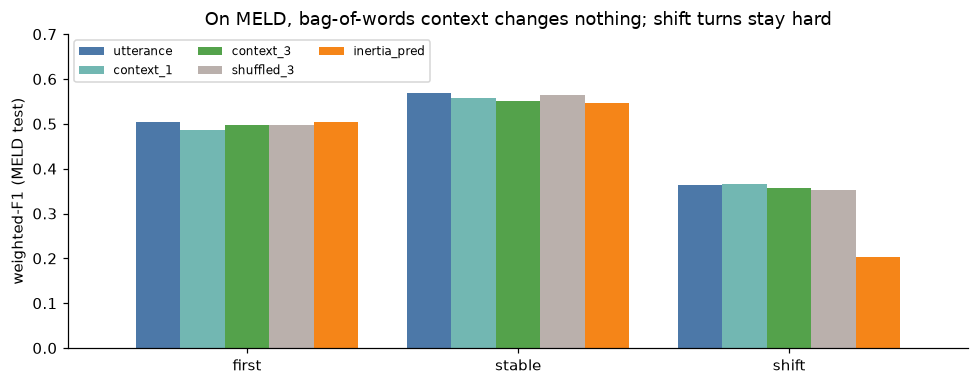

In [5]:
# inertia_oracle is left out: it is 1.0 on stable and 0.0 on shift turns by definition
ax = overview.loc[MODELS[:-1], ["first", "stable", "shift"]].T.plot.bar(
    figsize=(9, 3.6), width=0.82, color=["#4C78A8", "#72B7B2", "#54A24B", "#BAB0AC", "#F58518"])
ax.set(ylabel="weighted-F1 (MELD test)", xlabel="", ylim=(0, 0.7),
       title="On MELD, bag-of-words context changes nothing; shift turns stay hard")
ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(REPORTS / "figures" / "quick_baselines_meld.png")

**Where does the context gain come from?** Paired bootstrap of weighted-F1 differences against `utterance`, per stratum (1,000 dialogue-level resamples).

In [6]:
rows = []
for model in ["context_1", "context_3", "shuffled_3"]:
    for stratum in ["all", "first", "stable", "shift"]:
        mask = None if stratum == "all" else test["stratum"] == stratum
        r = paired_bootstrap(test, "utterance", model, mask=mask, seed=SEED)
        rows.append({"model": model, "stratum": stratum, **r})
gains = pd.DataFrame(rows).set_index(["model", "stratum"])
gains.to_csv(REPORTS / "tables" / "quick_baselines_meld_gains.csv")
gains

diff  ci_low  ci_high     n
model      stratum                              
context_1  all     -0.008  -0.022    0.006  2610
           first   -0.017  -0.041    0.010   746
           stable  -0.011  -0.035    0.013   861
           shift    0.003  -0.023    0.025  1003
context_3  all     -0.011  -0.025    0.003  2610
           first   -0.007  -0.033    0.019   746
           stable  -0.016  -0.038    0.006   861
           shift   -0.007  -0.031    0.015  1003
shuffled_3 all     -0.008  -0.022    0.005  2610
           first   -0.007  -0.036    0.021   746
           stable  -0.002  -0.023    0.020   861
           shift   -0.010  -0.031    0.010  1003

In [7]:
per_type = table["weighted_f1"].unstack("group")[
    [c for c in table.index.get_level_values("group").unique() if c.startswith("shift:")]]
per_type.columns = [c.removeprefix("shift:") for c in per_type.columns]
per_type.loc["n"] = table.loc["utterance", "n"][[f"shift:{c}" for c in per_type.columns]].to_numpy()
per_type.reindex(MODELS + ["n"])

,onset,offset,surprise,within_negative,valence_flip
model,,,,,
utterance,0.317,0.893,0.350,0.176,0.243
context_1,0.320,0.855,0.380,0.190,0.339
context_3,0.324,0.867,0.346,0.157,0.257
shuffled_3,0.321,0.880,0.347,0.106,0.231
inertia_pred,0.126,0.759,0.084,0.127,0.135
inertia_oracle,0.000,0.000,0.000,0.000,0.000
n,355.000,340.000,158.000,81.000,69.000


**How much is a perfect shift detector worth?** Upper bounds for ShiftAware's inertia gate: on stable turns use a prior, elsewhere the text model. With a *gold* prior that is the ceiling; with the text model's own earlier predictions as the prior it shows whether copying predictions is enough.

In [8]:
is_stable = test["stratum"] == "stable"
test["gate_oracle"] = np.where(is_stable, test["emotion"], test["utterance"])
test["gate_pred_prior"] = np.where(is_stable, test["inertia_pred"], test["utterance"])
pd.DataFrame({m: scores(test["emotion"], test[m])
              for m in ["utterance", "gate_pred_prior", "gate_oracle"]}).T

,n,weighted_f1,macro_f1,micro_f1_no_neutral,accuracy
utterance,2610.0,0.466,0.284,0.290,0.518
gate_pred_prior,2610.0,0.459,0.274,0.280,0.510
gate_oracle,2610.0,0.617,0.461,0.504,0.644


In [9]:
print("Class-balanced utterance model (overall):")
pd.DataFrame({m: scores(test["emotion"], test[m]) for m in ["utterance", "utterance_balanced"]}).T

Class-balanced utterance model (overall):


,n,weighted_f1,macro_f1,micro_f1_no_neutral,accuracy
utterance,2610.0,0.466,0.284,0.290,0.518
utterance_balanced,2610.0,0.421,0.308,0.331,0.400


## DailyDialog (de-duplicated test set)

In [10]:
dd = load("dailydialog", splits=("train", "dev", "test_dedup"))
dd_parts = {s: dd[dd["split"] == ("test_dedup" if s == "test" else s)]
            for s in ["train", "dev", "test"]}
dd_y = {s: p["emotion"].to_numpy() for s, p in dd_parts.items()}
dd_ctx3 = {s: previous_turns(p, 3) for s, p in dd_parts.items()}
dd_configs = {
    "utterance": {s: [p["text"]] for s, p in dd_parts.items()},
    "context_3": {s: [p["text"], dd_ctx3[s]] for s, p in dd_parts.items()},
}
dd_test = dd_parts["test"].copy()
for name, blocks in dd_configs.items():
    print(name)
    dd_test[name] = tune_and_predict(blocks, dd_y, "micro_f1_no_neutral", grid=(1, 4, 16))
prev_pred = dd_test.groupby(["dialogue_id", "speaker"], sort=False)["utterance"].shift(1)
dd_test["inertia_pred"] = prev_pred.fillna(dd_test["utterance"])
dd_test["inertia_oracle"] = dd_test["prev_emotion"].fillna(dd_test["utterance"])

DD_MODELS = ["utterance", "context_3", "inertia_pred", "inertia_oracle"]
dd_table = pd.concat({m: stratified_scores(dd_test, m) for m in DD_MODELS}, names=["model"])
dd_table.to_csv(REPORTS / "tables" / "quick_baselines_dailydialog.csv")
dd_overview = dd_table["micro_f1_no_neutral"].unstack("group")[["all", "first", "stable", "shift"]]
print(f"de-duplicated test: {len(dd_test):,} utterances, {dd_test['dialogue_id'].nunique()} dialogues")
dd_overview.reindex(DD_MODELS)

utterance


  C=16   dev micro_f1_no_neutral=0.516
context_3


  C=4    dev micro_f1_no_neutral=0.524


de-duplicated test: 7,019 utterances, 891 dialogues


group,all,first,stable,shift
model,,,,
utterance,0.454,0.434,0.350,0.554
context_3,0.473,0.421,0.414,0.545
inertia_pred,0.278,0.434,0.386,0.092
inertia_oracle,0.444,0.434,1.000,0.000


In [11]:
pd.DataFrame([
    {"stratum": s, **paired_bootstrap(dd_test, "utterance", "context_3", metric="micro_f1_no_neutral",
                                      mask=None if s == "all" else dd_test["stratum"] == s, seed=SEED)}
    for s in ["all", "first", "stable", "shift"]]).set_index("stratum")

,diff,ci_low,ci_high,n
stratum,,,,
all,0.020,-0.001,0.040,7019
first,-0.013,-0.059,0.033,1782
stable,0.064,0.032,0.099,4295
shift,-0.009,-0.041,0.019,942


## Findings

**1 · There is a large shift gap even without context.** The utterance-only model scores 0.568 weighted-F1 on stable turns and 0.363 on shift turns. Onsets (neutral to emotion, 0.317) are the hard part; offsets back to neutral are easy (0.893).

**2 · Bag-of-words context does nothing on MELD.** Adding the previous 1 or 3 utterances changes weighted-F1 by −1.6 to +0.3 points in every stratum, every interval spans zero, and the shuffled-context control behaves the same. A TF-IDF model cannot use MELD's conversational context, so H1 has to be tested with the transformer models (B3 vs B4).

**3 · DailyDialog's context gain is concentrated on stable turns.** On the shared `test_dedup` split (891 dialogues, 7,019 utterances), three previous turns add 2.0 points of micro-F1 excluding neutral overall (95% dialogue-bootstrap CI −0.1 to +4.0). The overall interval includes zero. Stable turns improve by 6.4 points (CI +3.2 to +9.9); shift turns change by −0.9 points (CI −4.1 to +1.9), with no clear benefit on shifts.

**4 · Inertia is only valuable with an accurate prior.** Copying the speaker's previous *gold* emotion beats the text model in aggregate (0.475 vs 0.466 weighted-F1), but copying their previous *predicted* emotion drops to 0.396 and collapses on shift turns (0.203). A perfect shift detector with a gold prior would lift MELD to 0.617; with copied predictions as the prior it gives 0.459, no gain. ShiftAware's prior therefore has to come from a learned speaker state, and its gate must know when to stop trusting it.

**5 · Class balancing trades weighted-F1 for macro-F1.** Balanced class weights raise macro-F1 from 0.284 to 0.308 and lower weighted-F1 from 0.466 to 0.421. This supports the B4+ plan behind requirement R3, which is judged on macro-F1.

**Next:** fine-tune RoBERTa without (B3) and with context (B4) and rerun this stratified comparison; add `turn_gap` to the Markov forecasting baseline.